# Finding what the classifier was never taught: anomaly detection with FLARE and LUNA

**Rubin ML Training School 2026 · Day 2 · Anomaly-detection session**

A classifier trained on six classes always answers with one of the six, even for a nova, a luminous red nova or a luminous blue variable. FLARE therefore carries an **anomaly layer**: [LUNA](https://github.com/asasli/luna) computes many anomaly scores from FLARE's own representation of each object and combines them into one score, and the alarm threshold is set at a chosen **false-alarm rate**.

In this notebook we (1) run FLARE's shipped anomaly layer on the benchmark, (2) rebuild it ourselves with LUNA to see which scores find what, (3) test it on a class hidden from training, and (4) fall into the most common trap of anomaly detection.

Levels: 🟢 run and read · 🟡 modify (*Try it*) · 🔴 challenge.

## 0. Setup
The same models and benchmark as the morning notebook (downloaded again if needed).

In [1]:
# %pip install "git+https://github.com/applecider-ml/flare"      # only if `import flare` fails
import tarfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flare
from flare import consensus
from flare.config import PKG_ROOT
from flare.benchmark import load_split, SIX as CLASSES

BASE = "https://raw.githubusercontent.com/applecider-ml/flare/main/benchmark/"
DATA = Path("data/flare_benchmark")
for name in ["features_all.parquet", "hosts.csv", "hosts_photoz.csv", "context_gaia_wise.csv", "ps1_position.csv",
             "splits/train.csv", "splits/val.csv", "splits/test.csv", "splits/anomaly.csv", "light_curves.tar.gz"]:
    path = DATA / name
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True); urllib.request.urlretrieve(BASE + name, path)
if not (DATA / "events").exists():
    with tarfile.open(DATA / "light_curves.tar.gz") as tar:
        tar.extractall(DATA, **({"filter": "data"} if hasattr(tarfile, "data_filter") else {}))

data = {s: load_split(s, root=DATA) for s in ["train", "val", "test", "anomaly"]}
X, y, table = ({s: d[i] for s, d in data.items()} for i in range(3))
has = X["anomaly"].notna().any(axis=1).to_numpy() & X["anomaly"]["n_obs_total"].notna().to_numpy()
X["anomaly"], table["anomaly"] = X["anomaly"][has].reset_index(drop=True), table["anomaly"][has].reset_index(drop=True)
print("out-of-taxonomy objects:", table["anomaly"].bts_type.value_counts().to_dict())

clf = flare.load_classifier()
cons = consensus.load(PKG_ROOT / "models" / "bts6")          # FLARE's anomaly layer: a LUNA pipeline
print("anomaly scorers:", list(cons.pipeline.active_methods))

def load_lc(obj_id):
    z = np.load(DATA / "events" / f"{obj_id}.npz"); d = pd.DataFrame(z["data"], columns=[str(c) for c in z["columns"]])
    return pd.DataFrame({"t": d["dt"], "band": d["band_id"].astype(int), "mag": 23.9 - 2.5 * d["logflux"], "mag_err": 2.5 * d["logflux_err"]})

out-of-taxonomy objects: {'nova': 37, 'LBV': 6, 'LRN': 4, 'ILRT': 3, 'Ca-rich': 2}


anomaly scorers: ['msp', 'entropy', 'energy', 'odin', 'mahal_global', 'mahal_class', 'mahal_within', 'knn', 'typicality', 'gmm', 'iforest', 'lof', 'pca_recon', 'mrs']


The 52 objects of the anomaly split are spectroscopically confirmed transients that belong to **none** of the six classes: classical novae, luminous blue variables (LBV), luminous red novae (LRN), intermediate-luminosity red transients (ILRT) and calcium-rich transients. (The fast blue optical transient AT 2018cow, the 53rd object, has no precomputed features in this table.)

## 1. FLARE's anomaly layer out of the box

For every object the layer returns a **consensus score** (higher = more unusual), a **p-value** (the fraction of normal calibration objects that look at least as unusual) and an **alarm** at false-alarm rates of 1%, 5% and 10%. Its thresholds were set on known objects of the validation split, so the test split gives an honest false-alarm rate.

In [2]:
def flare_anomaly(Xs):
    out = cons.score(Xs.reindex(columns=clf.feature_names), clf.ad_space)
    return pd.DataFrame({"consensus": [o["consensus"] for o in out], "p_value": [o["p_value"] for o in out]})

A_test, A_rare = flare_anomaly(X["test"]), flare_anomaly(X["anomaly"])
family = np.where(table["anomaly"].bts_type == "nova", "nova (parent class CV exists)", "no parent class")
rows = []
for far in [0.01, 0.05, 0.10]:
    row = {"target FAR": far, "realised FAR on known test objects": (A_test.p_value <= far).mean()}
    for g in ["nova (parent class CV exists)", "no parent class"]:
        row[f"detected: {g}"] = f"{int((A_rare.p_value[family == g] <= far).sum())} / {int((family == g).sum())}"
    rows.append(row)
pd.DataFrame(rows).round(3)

,target FAR,realised FAR on known test objects,detected: nova (parent class CV exists),detected: no parent class
0,0.01,0.000,0 / 37,0 / 15
1,0.05,0.016,7 / 37,0 / 15
2,0.10,0.046,19 / 37,1 / 15


Read the table:

* **realised FAR**: the fraction of *known* test objects flagged, the price of the alarm.
* **detected**: how many out-of-taxonomy objects pass the threshold.

The realised rates sit *below* their targets. The shipped thresholds were set on the light curves that Fritz delivers to the service, which have several times more points than the benchmark light curves; on the sparser benchmark the layer is conservative. Keep this in mind for section 4.

At 1% nothing is found, and at 5% a handful of novae. This is the honest picture: most of these objects resemble a known class in *g* and *r* (an ILRT looks like a faint type II SN, a nova like a CV outburst), and what separates them (narrow lines, nebular calcium, the progenitor) is in a spectrum. Blind detection stalls where the physics predicts it should.

### Ranking for follow-up
An alarm is a yes/no answer at one threshold. In practice a reviewer inspects a ranked list, most unusual first.

In [3]:
pool = pd.concat([table["test"][["obj_id", "cls"]].rename(columns={"cls": "true type"}).assign(**A_test),
                  table["anomaly"][["obj_id", "bts_type"]].rename(columns={"bts_type": "true type"}).assign(**A_rare)], ignore_index=True)
pool["classifier says"] = np.r_[clf.predict(X["test"].reindex(columns=clf.feature_names)), clf.predict(X["anomaly"].reindex(columns=clf.feature_names))]
pool = pool.sort_values("consensus", ascending=False).reset_index(drop=True)
for k in [20, 50, 100, 200]:
    print(f"top {k:3d}: {int((~pool['true type'].head(k).isin(CLASSES)).sum())} out-of-taxonomy objects")
pool.head(20).style.apply(lambda r: ["background: #fde2ea" if r["true type"] not in CLASSES else "" for _ in r], axis=1)

top  20: 7 out-of-taxonomy objects
top  50: 13 out-of-taxonomy objects
top 100: 19 out-of-taxonomy objects
top 200: 30 out-of-taxonomy objects


,obj_id,true type,consensus,p_value,classifier says
0,ZTF22aahgxdt,SN_Ia,0.946220,0.028571,SN_CC
1,ZTF22aazmooy,nova,0.941448,0.038095,SN_CC
2,ZTF21abfmbix,SN_Ia,0.940464,0.038095,SN_Ia
3,ZTF21acbcfmh,nova,0.940161,0.038095,SN_Ia
4,ZTF18aahfqbc,SN_CC,0.935767,0.018692,SN_CC
5,ZTF18aazrdpr,CV,0.935540,0.038095,SN_CC
6,ZTF20abzumlr,SLSN,0.926072,0.038095,SN_Ia
7,ZTF18aagstdc,SN_Ia,0.909938,0.028037,SN_CC
8,ZTF18acbwaxk,SN_CC,0.905620,0.019802,SN_CC
9,ZTF22aatixbc,nova,0.901757,0.038095,SN_CC


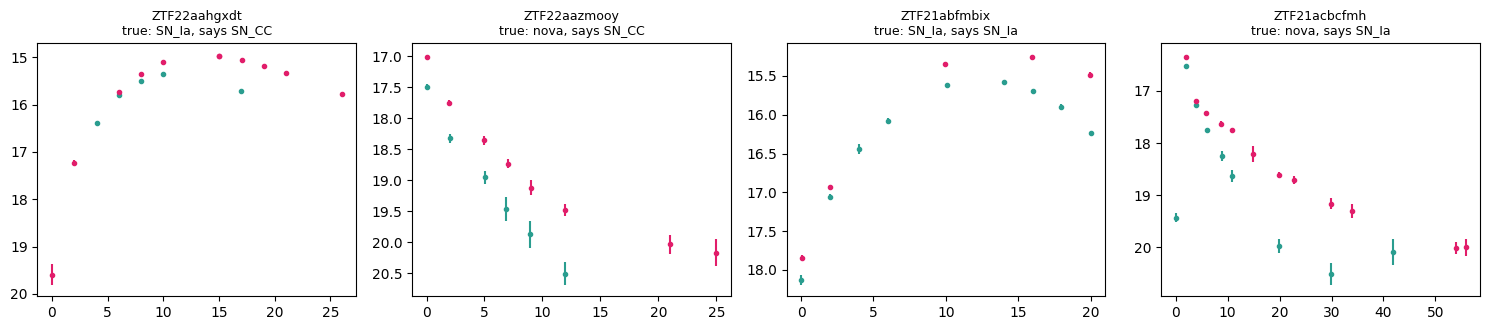

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (_, r) in zip(axes, pool.head(4).iterrows()):
    lc = load_lc(r.obj_id)
    for b, col in [(0, "#2a9d8f"), (1, "#e11d6a"), (2, "#f4a261")]:
        s = lc[lc.band == b]; ax.errorbar(s.t, s.mag, s.mag_err, fmt="o", ms=3, color=col)
    ax.invert_yaxis(); ax.set_title(f"{r.obj_id}\ntrue: {r['true type']}, says {r['classifier says']}", fontsize=9)
fig.tight_layout()

🟡 *Try it*: a reviewer can look at about 50 objects a night. Is the ranking useful at that budget even when the 1% alarm finds little? Which classes of *known* objects reach the top of the list, and why?

## 2. Inside the layer: rebuild it with LUNA

LUNA does not care which model produced its inputs. It asks for two arrays per object:

* **logits** $(N, C)$: the raw class scores of the classifier before the softmax. *Uncertainty* scorers read them: a flat distribution means the classifier is unsure.
* **embeddings** $(N, d)$: a vector that describes the object. *Distance* and *density* scorers read them: an object far from every class, or in a sparse region, is unusual.

FLARE provides both: the logits of its anomaly booster (`clf.ad_space`) and its scaled features (`cons.embed`). We fit the scorers on the training split, set the thresholds on one half of the test split and evaluate on the other half, so that no object is used twice.

In [5]:
from luna import LUNAPipeline

def representation(Xs, labels=None):
    Xs = Xs.reindex(columns=clf.feature_names)
    out = {"embeddings": cons.embed(Xs), "logits": clf.ad_space.predict(Xs.reindex(columns=clf.ad_space.feature_name()), raw_score=True)}
    if labels is not None:
        out["labels"] = labels
    return out

half = np.random.default_rng(0).random(len(X["test"])) < 0.5
calib, evaln = X["test"][half].reset_index(drop=True), X["test"][~half].reset_index(drop=True)

SCORERS = ["msp", "entropy", "energy", "mahal_global", "mahal_class", "knn", "gmm", "iforest", "typicality"]
pipe = LUNAPipeline(combiner="rank", target_far=[0.01, 0.05, 0.10], scorers=SCORERS)
pipe.fit(representation(X["train"], y["train"]))
pipe.fit_blind(representation(X["val"]), calibration_data=representation(calib))
res = pipe.evaluate(representation(evaln), representation(X["anomaly"]), groups=family, methods=True)
res.query("target_far == 0.05 and group == 'all'")[["rule", "realised_fpr", "auroc", "detected", "n", "det_rate"]].round(3)

  [LUNA] fit msp in 0.0s


  [LUNA] fit entropy in 0.0s


  [LUNA] fit energy in 0.0s


  [LUNA] fit mahal_global in 0.0s


  [LUNA] fit mahal_class in 0.0s


  [LUNA] fit knn in 0.0s


... (2 outputs left out)

  [LUNA] fit typicality in 0.0s


  [LUNA] Fitted 9 scorers: ['msp', 'entropy', 'energy', 'mahal_global', 'mahal_class', 'knn', 'gmm', 'iforest', 'typicality']


  [LUNA] Threshold @ FAR=1.0%: 0.9523 on 765 calibration samples
  [LUNA] Threshold @ FAR=5.0%: 0.8758 on 765 calibration samples
  [LUNA] Threshold @ FAR=10.0%: 0.8149 on 765 calibration samples


,rule,realised_fpr,auroc,detected,n,det_rate
3,ensemble,0.048,0.867,25,52,0.481
12,msp,0.059,0.748,10,52,0.192
21,entropy,0.056,0.768,22,52,0.423
30,energy,0.054,0.766,17,52,0.327
39,mahal_global,0.035,0.841,8,52,0.154
48,mahal_class,0.033,0.807,8,52,0.154
57,knn,0.031,0.874,12,52,0.231
66,gmm,0.042,0.876,20,52,0.385
75,iforest,0.032,0.865,19,52,0.365
84,typicality,0.041,0.750,5,52,0.096


* **auroc**: how well the score ranks anomalies above known objects over all thresholds (0.5 = chance, 1 = perfect).
* **det_rate**: the fraction of anomalies flagged at the 5% threshold.
* **ensemble**: the *blind consensus*, the mean percentile rank over all scorers; it needs no example of an anomaly.

Which family of scorers carries the detection: uncertainty (msp, entropy, energy), distance (mahal, knn, typicality) or density (gmm, iforest)?

🟡 *Try it*: show the novae and the no-parent families separately: `res.query("target_far == 0.05 and group != 'all'")`.

## 3. A controlled test: hide one class

FLARE has seen every one of its six classes. To test whether the detector finds a *new* class, we train a small classifier without the **TDEs**, so that every TDE becomes an anomaly, and give its logits to LUNA.

In [6]:
import lightgbm as lgb
HIDE = "TDE"
known = [c for c in CLASSES if c != HIDE]
def part(s):
    keep = (table[s].cls != HIDE).to_numpy()
    return X[s][keep].reset_index(drop=True), table[s].cls[keep].map(known.index).to_numpy()
(Xtr, ytr), (Xva, yva), (Xte, yte) = part("train"), part("val"), part("test")
X_hidden = pd.concat([X[s][(table[s].cls == HIDE).to_numpy()] for s in ["train", "val", "test"]], ignore_index=True)

model5 = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, class_weight="balanced", random_state=0, verbose=-1)
model5.fit(Xtr[clf.feature_names], ytr, eval_set=[(Xva[clf.feature_names], yva)], callbacks=[lgb.early_stopping(100, verbose=False)])

def rep5(Xs, labels=None):
    Xs = Xs.reindex(columns=clf.feature_names)
    out = {"embeddings": cons.embed(Xs), "logits": model5.predict(Xs, raw_score=True)}
    if labels is not None:
        out["labels"] = labels
    return out

pipe5 = LUNAPipeline(combiner="rank", target_far=[0.01, 0.05, 0.10], scorers=SCORERS)
pipe5.fit(rep5(Xtr, ytr))
pipe5.fit_blind(rep5(Xva))
res5 = pipe5.evaluate(rep5(Xte), rep5(X_hidden), methods=True)
res5.query("target_far == 0.05")[["rule", "realised_fpr", "auroc", "detected", "n", "det_rate"]].round(3)

  [LUNA] fit msp in 0.0s


  [LUNA] fit entropy in 0.0s


  [LUNA] fit energy in 0.0s


  [LUNA] fit mahal_global in 0.0s


  [LUNA] fit mahal_class in 0.0s


  [LUNA] fit knn in 0.0s


... (2 outputs left out)

  [LUNA] fit typicality in 0.0s


  [LUNA] Fitted 9 scorers: ['msp', 'entropy', 'energy', 'mahal_global', 'mahal_class', 'knn', 'gmm', 'iforest', 'typicality']


  [LUNA] Threshold @ FAR=1.0%: 0.9354 on 782 calibration samples
  [LUNA] Threshold @ FAR=5.0%: 0.8733 on 782 calibration samples
  [LUNA] Threshold @ FAR=10.0%: 0.8156 on 782 calibration samples


,rule,realised_fpr,auroc,detected,n,det_rate
1,ensemble,0.051,0.763,9,68,0.132
4,msp,0.045,0.908,36,68,0.529
7,entropy,0.062,0.935,50,68,0.735
10,energy,0.059,0.978,60,68,0.882
13,mahal_global,0.052,0.535,4,68,0.059
16,mahal_class,0.052,0.509,3,68,0.044
19,knn,0.043,0.639,2,68,0.029
22,gmm,0.045,0.696,2,68,0.029
25,iforest,0.043,0.575,2,68,0.029
28,typicality,0.047,0.529,2,68,0.029


The hidden TDEs are found far more easily than the real out-of-taxonomy objects of section 2: a class chosen to be hidden is usually distinct, so hidden-class tests are optimistic.

Does the consensus beat the best single scorer here? It averages the ranks of all scorers, so scorers that are close to chance dilute the one that sees the anomaly. A blind consensus is robust when we do not know what the anomaly looks like; when we do, a well-chosen scorer wins.

🟡 *Try it*: set `HIDE = "SLSN"` or `"CV"` and rerun the section; or build the pipeline with the uncertainty scorers only, `["msp", "entropy", "energy"]`.

## 4. A trap: calibrate on the stream you score

The threshold guarantees a false-alarm rate **for objects like the calibration objects**. Suppose a different pipeline (another broker, another photometry, a shallower survey) measures the same features of the same transients with more scatter. Nothing about the transients changed, but the inputs did.

In [7]:
def other_pipeline(Xs, scatter=0.30, seed=1):
    """The same objects, every feature measured with a relative scatter (missing values stay missing)."""
    return Xs * (1 + scatter * np.random.default_rng(seed).standard_normal(Xs.shape))

RATES = [0.01, 0.05, 0.10]
for name, Xs in [("our pipeline", X["test"]), ("other pipeline", other_pipeline(X["test"]))]:
    p = flare_anomaly(Xs).p_value
    print(f"{name:15s}: known test objects flagged by FLARE at nominal 1 / 5 / 10%: "
          + " / ".join(f"{(p <= a).mean():.1%}" for a in RATES))

our pipeline   : known test objects flagged by FLARE at nominal 1 / 5 / 10%: 0.0% / 1.6% / 4.6%


other pipeline : known test objects flagged by FLARE at nominal 1 / 5 / 10%: 0.3% / 8.7% / 22.5%


At 5% and 10% the false-alarm rate rises several-fold: the detector now partly flags a change in the inputs, not a new kind of transient. The same happens when a model trained on one survey scores another one, or simulations. In production, FLARE's thresholds set on the benchmark light curves gave about four times the nominal rate on the denser photometry that Fritz supplies, and recalibrating on that photometry fixed it.

The fix needs no anomaly and no retraining: **recalibrate on normal objects of the new stream.** We do it with our own pipeline of section 2:

In [8]:
for name, cal, ev in [("calibrated on our pipeline", calib, other_pipeline(evaln)),
                      ("recalibrated on the other pipeline", other_pipeline(calib, seed=2), other_pipeline(evaln))]:
    pipe.calibrate(representation(cal), verbose=False)
    flags = pipe.predict(representation(ev))["flags"]
    print(f"{name:36s}: known objects flagged at nominal 1 / 5 / 10%: " + " / ".join(f"{flags[a].mean():.1%}" for a in RATES))
pipe.calibrate(representation(calib), verbose=False)          # back to the normal calibration

calibrated on our pipeline          : known objects flagged at nominal 1 / 5 / 10%: 1.7% / 14.9% / 31.4%


recalibrated on the other pipeline  : known objects flagged at nominal 1 / 5 / 10%: 0.5% / 4.8% / 10.0%


🟡 *Try it*: change `scatter` to 0.1 and 0.5. How large must the change in the inputs be before the alarm rate doubles?

🔴 **Challenge**: a claim such as "98% recall at 1% false-alarm rate" on objects from one survey, with the threshold set on another, measures the difference between the surveys. Design the check that would expose it.

## 5. Beyond one alarm (discussion and challenges)

🔴 **Re-analysis.** On Fritz a source is analysed again at every new detection, about fifty times in a hundred days. With a 1% alarm at each analysis, about 10% of normal sources are flagged at least once. How would you define a false-alarm rate *per unit time* instead? (FLARE's answer: `flare/lifetime.py`.)

🔴 **A few labels.** Once a reviewer confirms a handful of novae, `pipe.fit_combiner(id_data, ood_data)` learns a supervised combination of the scorers. Fit it with five novae and test it on the others. Then think about *which* five to label: Sasli & Coughlin 2026 ([arXiv:2611.03250](https://arxiv.org/abs/2611.03250)) show that the members a detector ranks highest are the least typical of their class, so a new class learned from anomaly-ranked confirmations is recognised more slowly than one learned from random members.

🔴 **Embeddings.** Replace `cons.embed` with the leaf indices of the trees (`clf.ad_space.predict(X, pred_leaf=True)`, one-hot encoded) or with the AppleCiDEr transformer embedding, and compare the AUROC of the distance scorers.

## Take-away

1. A classifier always answers; novelty needs its own score, and many scores exist.
2. Set the threshold at a false-alarm rate on held-out normal objects, and report the realised rate.
3. Hidden-class tests are optimistic; real out-of-taxonomy objects are harder because the light curve does not carry what defines them.
4. Calibrate on the stream you score.

*Further reading*: Sasli et al. 2026, [arXiv:2610.30656](https://arxiv.org/abs/2610.30656) (FLARE); Sasli et al. 2026, [arXiv:2607.08044](https://arxiv.org/abs/2607.08044) (LUNA on spectra in ASTRANet).